In [1]:
# !pip3 install roboflow ultralytics
# paste here your code snippet from roboflow

%pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="P9tE9EIYzpyRWTl1s80R")
project = rf.workspace("ai-model-training-rndre").project("smartmirror-ycsnp")
version = project.version(2)
dataset = version.download("yolo26")
                


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to smartmirror-2 in yolo26:: 100%|██████████| 5947/5947 [00:27<00:00, 219.53it/s]


### Train model locally

In [ ]:
from ultralytics import YOLO

def main():
    model = YOLO(model="yolo26n.pt")
    # model.train(data="path to your data.yaml file", epochs=25, imgsz=640, verbose=True, batch=8)
    model.train(data="./bees-2/data.yaml", epochs=25, imgsz=640, verbose=True, batch=8)
    model.val()
    model.export()
if __name__ == '__main__':
    main()

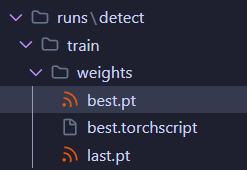

### Load model

In [ ]:
import os
from os import path
print(os.getcwd())

In [ ]:
# Load your trained model
model = YOLO("path to your best.pt file")

### Prediction
Default ultralytics visualization.<br>
The output can look different depending if your model originates from roboflow or is trained locally.

In [ ]:
# Make a prediction

path = "path to your test image"
result = model.predict(path)
result = result[0] if isinstance(result, list) else result
result.save("prediction_default.jpg")

from IPython.display import Image
Image("prediction_default.jpg")

### Count the instances from a class

In [ ]:
# !pip3 install supervision
import supervision as sv

print(model.names)
def get_keys_from_value(d, val):
    return [k for k, v in d.items() if v == val]

detections = sv.Detections.from_ultralytics(result)
detections = detections[detections.class_id == get_keys_from_value(model.names, 'Drone')] # if necessary replace by your own class
print("Amount of drones: ",len(detections))

### Create a simple interface with gradio
https://www.gradio.app/

In [11]:
%pip install gradio supervision
import numpy as np
import PIL.Image as Image
import gradio as gr
from ultralytics import YOLO

model = YOLO(r"C:\HOWEST\2025-2026\project one\2025-26-projectone-ctai-ProksaDominik\Laptop\smartmirror-2\best.pt")

def predict_image(img, conf_threshold, iou_threshold):
    if img is None:
        return None, "No one detected"

    img_np = np.array(img.convert("RGB")) if hasattr(img, "convert") else np.array(img)

    results = model.predict(
        source=img_np,
        conf=conf_threshold,
        iou=iou_threshold,
        imgsz=640,
        agnostic_nms=True,
        verbose=False,
    )

    result = results[0]
    im_array = result.plot()
    im = Image.fromarray(im_array[..., ::-1])

    if result.boxes is not None and len(result.boxes):
        detected = [model.names[int(c)] for c in result.boxes.cls]
        summary = "Detected: " + ", ".join(detected)
    else:
        summary = "No one detected"

    return im, summary


with gr.Blocks(theme=gr.themes.Monochrome()) as demo:
    gr.Markdown("## Real-time face recognition")
    with gr.Row():
        webcam = gr.Image(sources=["webcam"], streaming=True, type="pil", label="Camera")
        output_img = gr.Image(type="pil", label="Who is here?")
    with gr.Row():
        conf = gr.Slider(0, 1, value=0.25, label="Confidence threshold")
        iou = gr.Slider(0, 1, value=0.45, label="IoU threshold")
    name_out = gr.Textbox(label="Detected person", text_align="center")

    webcam.stream(
        fn=predict_image,
        inputs=[webcam, conf, iou],
        outputs=[output_img, name_out],
    )

demo.launch()

* Running on local URL:  http://127.0.0.1:7869
* To create a public link, set `share=True` in `launch()`.
